In [1]:
from omegaconf import OmegaConf
import matplotlib.pyplot as plt
import numpy as np

from bio_image_datasets.pathocell2_dataset import PathoCell2Dataset
from benchmark.utils.utils import prep_datasets

In [2]:
pathocell2_path = '/fast/AG_Kainmueller/jannik/pathocellv2_annot/data/phenocell/1-1/'
pathocell2_dataset = PathoCell2Dataset(pathocell2_path)
print(len(pathocell2_dataset))
print(pathocell2_dataset.get_he(0).shape)

140
(3, 1440, 1920)


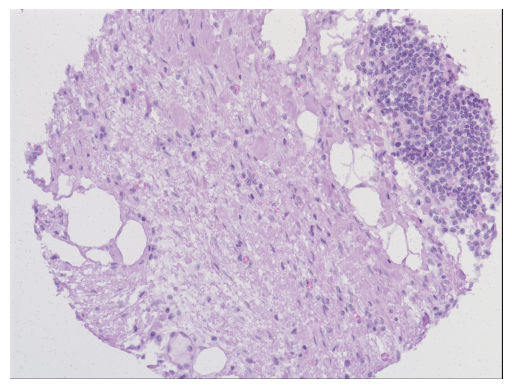

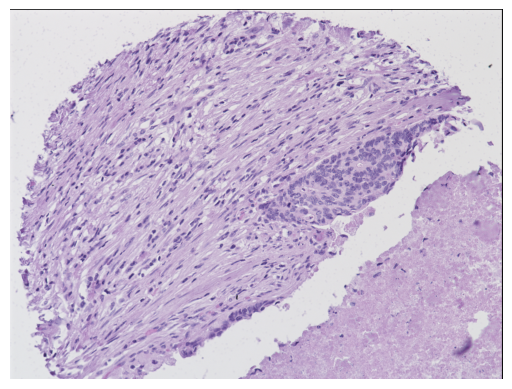

In [3]:
pathocell2_img_0 = np.transpose(pathocell2_dataset.get_he(0), (1, 2, 0))
pathocell2_img_100 = np.transpose(pathocell2_dataset.get_he(100), (1, 2, 0))

plt.imshow(pathocell2_img_0 /np.max(pathocell2_img_0))
plt.axis('off')
plt.show()
plt.imshow(pathocell2_img_100 / np.max(pathocell2_img_100))
plt.axis('off')
plt.show()

In [4]:
pathocell2_cfg_path = '/fast/AG_Kainmueller/nkoreub/Pathology-Foundation-Model-Benchmark/configs/config_unetr_pathocell2.yaml'
pathocell2_cfg = OmegaConf.load(pathocell2_cfg_path)

In [5]:
train_pathocell2, val_pathocell2, test_pathocell2, label_dict_pathocell2 = prep_datasets(pathocell2_cfg)
len_pathocell2 = len(train_pathocell2)+len(val_pathocell2)+len(test_pathocell2)
print(len_pathocell2)

6867


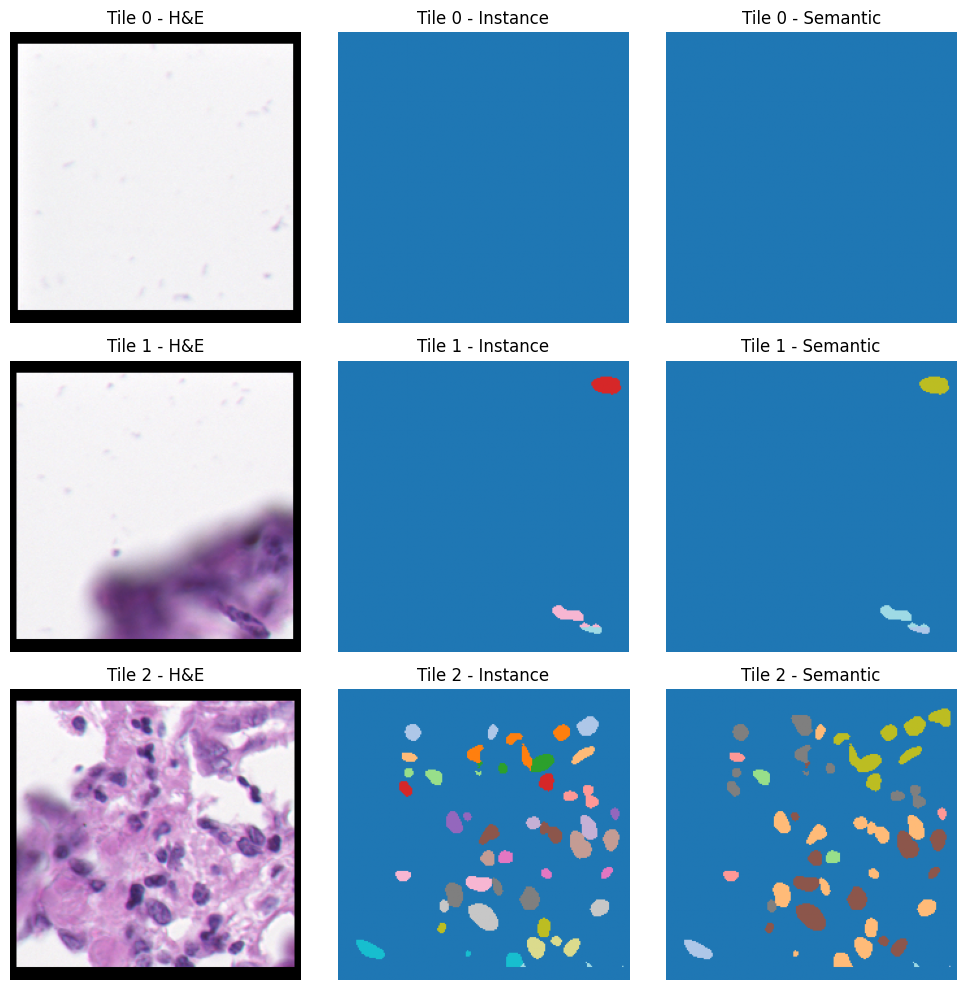

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i in range(3):
    # H&E image
    he = np.transpose(val_pathocell2[i]['image'], (1, 2, 0))
    axes[i, 0].imshow(he)
    axes[i, 0].set_title(f"Tile {i} - H&E")

    # Instance mask
    inst = val_pathocell2[i]['instance_mask']
    axes[i, 1].imshow(inst, cmap="tab20")
    axes[i, 1].set_title(f"Tile {i} - Instance")

    # Semantic mask
    sem = val_pathocell2[i]['semantic_mask']
    axes[i, 2].imshow(sem, cmap="tab20")
    axes[i, 2].set_title(f"Tile {i} - Semantic")

    # Hide axes
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
count_instances_pathocell2 = 0
for i in range(len(train_pathocell2)):
    n_instances = len(np.unique(train_pathocell2[i]['instance_mask']))
    count_instances_pathocell2 = count_instances_pathocell2 + n_instances
avg_instances_pathocell2 = count_instances_pathocell2 / len(train_pathocell2)
print(avg_instances_pathocell2)

43.18790218790219


In [8]:
print(label_dict_pathocell2)

{'0': 'Background', '1': 'Tumor cells', '2': 'T Cells', '3': 'B Cells', '4': 'Plasma Cells', '5': 'NK Cells', '6': 'Macrophages', '7': 'Monocytes', '8': 'Granulocytes', '9': 'Endothelial Cells', '10': 'Smooth muscle Cells', '11': 'Fibroblasts', '12': 'Pericytes', '13': 'Dendritic Cells'}


In [9]:
unique_labels = []
for split in [train_pathocell2, val_pathocell2, test_pathocell2]:
    for i in range(len(split)):
        unique = np.unique(train_pathocell2[i]['semantic_mask'])
        unique_labels = np.union1d(unique_labels, unique)
print(unique_labels)

[ 0.  1.  2.  3.  4.  6.  8.  9. 10. 11. 12. 13.]
